In [1]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns

from tensorflow.keras.preprocessing import image
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input
from tensorflow.keras.layers import (
    Input, Conv2D, Dense, Dropout, GlobalAveragePooling2D, RandomRotation
)
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam

from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report

C:\Users\Thidar Khaing\.conda\envs\deepenv\Lib\site-packages\requests\__init__.py:92: RequestsDependencyWarning: Unable to find acceptable character detection dependency (chardet or charset_normalizer).
  warnings.warn(


In [2]:
dataset_dir = "D:/Deep Learning for Image/dataset"

img_height = 224
img_width = 224
batch_size = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_dir,
    validation_split=0.30,
    subset="training",
    seed=123,
    image_size=(img_height, img_width),
    batch_size=batch_size,
    label_mode="categorical"
)

temp_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_dir,
    validation_split=0.30,
    subset="validation",
    seed=123,
    image_size=(img_height, img_width),
    batch_size=batch_size,
    label_mode="categorical"
)

class_names = train_ds.class_names
num_classes = len(class_names)

print("Classes:", class_names)
print("Number of classes:", num_classes)

Found 1181 files belonging to 5 classes.
Using 827 files for training.
Found 1181 files belonging to 5 classes.
Using 354 files for validation.
Classes: ['bike', 'dogs', 'flowers', 'horses', 'human']
Number of classes: 5


In [3]:
# 15% validation and 15% testing
val_batches = tf.data.experimental.cardinality(temp_ds)

test_ds = temp_ds.take(val_batches // 2)
val_ds = temp_ds.skip(val_batches // 2)

class_names = train_ds.class_names

print("Classes:", class_names)
print("Number of classes:", len(class_names))

Classes: ['bike', 'dogs', 'flowers', 'horses', 'human']
Number of classes: 5


In [4]:
# Count number of batches
val_batches = tf.data.experimental.cardinality(val_ds).numpy()
test_batches = tf.data.experimental.cardinality(test_ds).numpy()

# Count images
val_images = sum(
    images.shape[0] for images, labels in val_ds
)

test_images = sum(
    images.shape[0] for images, labels in test_ds
)

print("Number of validation batches:", val_batches)
print("Number of testing batches:", test_batches)

print("Number of validation images:", val_images)
print("Number of testing images:", test_images)

Number of validation batches: 6
Number of testing batches: 6
Number of validation images: 162
Number of testing images: 192


In [5]:
train_ds = train_ds.map(
    lambda x, y: (preprocess_input(x), y)
)

val_ds = val_ds.map(
    lambda x, y: (preprocess_input(x), y)
)

test_ds = test_ds.map(
    lambda x, y: (preprocess_input(x), y)
)

In [6]:
from tensorflow.keras.layers import (
    Concatenate, MaxPooling2D,Flatten, Maximum, Average)

# Input layer
inputs = Input(shape=(224, 224, 3))

# Branch 1: 3x3 convolution
branch1 = Conv2D(32,(3, 3),padding='same',activation='relu',name='conv_3x3')(inputs)

# Branch 2: 5x5 convolution
branch2 = Conv2D(32,(5, 5),padding='same',activation='relu',name='conv_5x5')(inputs)

# Combine two branches
#merged = Concatenate(name='concatenate')([branch1, branch2])
merged = Average(name='avg')([branch1, branch2])

# Max pooling
x = MaxPooling2D(pool_size=(2, 2))(merged)

x = Conv2D(64,(3, 3),padding='same',activation='relu',name='conv_3x3_1')(x)
x = MaxPooling2D(pool_size=(2, 2))(x)

x = Conv2D(128,(3, 3),padding='same',activation='relu',name='conv_3x3_2')(x)
x = MaxPooling2D(pool_size=(2, 2))(x)

# Flatten layer
#x = Flatten()(x)
x = GlobalAveragePooling2D()(x)

# Fully connected layer
x = Dense(128,activation='relu')(x)

# Dropout
x = Dropout(0.5)(x)

# Output layer (5 classes)
outputs = Dense(5,activation='softmax')(x)

# Create model
model = Model(
    inputs=inputs,
    outputs=outputs
)

# Display model architecture
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)      │ (None, 224, 224, 3)       │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv_3x3 (Conv2D)             │ (None, 224, 224, 32)      │             896 │ input_layer[0][0]          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv_5x5 (Conv2D)             │ (None, 224, 224, 32)      │           2,432 │ input_layer[0][0]          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ avg (Average)                 │ (None, 224, 224, 32)      │               0 │ conv_3x3[0][0],            │
│                               │                           │                 │ conv_5x5[0][0]             │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ max_pooling2d (MaxPooling2D)  │ (None, 112, 112, 32)      │               0 │ avg[0][0]                  │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv_3x3_1 (Conv2D)           │ (None, 112, 112, 64)      │          18,496 │ max_pooling2d[0][0]        │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ max_pooling2d_1               │ (None, 56, 56, 64)        │               0 │ conv_3x3_1[0][0]           │
│ (MaxPooling2D)                │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv_3x3_2 (Conv2D)           │ (None, 56, 56, 128)       │          73,856 │ max_pooling2d_1[0][0]      │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ max_pooling2d_2               │ (None, 28, 28, 128)       │               0 │ conv_3x3_2[0][0]           │
│ (MaxPooling2D)                │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ global_average_pooling2d      │ (None, 128)               │               0 │ max_pooling2d_2[0][0]      │
│ (GlobalAveragePooling2D)      │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dense (Dense)                 │ (None, 128)               │          16,512 │ global_average_pooling2d[… │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dropout (Dropout)             │ (None, 128)               │               0 │ dense[0][0]                │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dense_1 (Dense)               │ (None, 5)                 │             645 │ dropout[0][0]              │
└───────────────────────────────┴───────────────────────────┴─────────────────┴────────────────────────────┘

 Total params: 112,837 (440.77 KB)

 Trainable params: 112,837 (440.77 KB)

 Non-trainable params: 0 (0.00 B)

In [7]:
model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5
)

Epoch 1/5


C:\Users\Thidar Khaing\.conda\envs\deepenv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


26/26 ━━━━━━━━━━━━━━━━━━━━ 42s 1s/step - accuracy: 0.3265 - loss: 2.4858 - val_accuracy: 0.3951 - val_loss: 1.3842
Epoch 2/5
26/26 ━━━━━━━━━━━━━━━━━━━━ 42s 2s/step - accuracy: 0.4680 - loss: 1.2979 - val_accuracy: 0.4198 - val_loss: 1.2987
Epoch 3/5
26/26 ━━━━━━━━━━━━━━━━━━━━ 38s 1s/step - accuracy: 0.5514 - loss: 1.1509 - val_accuracy: 0.5741 - val_loss: 1.0288
Epoch 4/5
26/26 ━━━━━━━━━━━━━━━━━━━━ 37s 1s/step - accuracy: 0.6082 - loss: 1.0116 - val_accuracy: 0.6667 - val_loss: 0.8766
Epoch 5/5
26/26 ━━━━━━━━━━━━━━━━━━━━ 34s 1s/step - accuracy: 0.6409 - loss: 0.9606 - val_accuracy: 0.6420 - val_loss: 0.9122


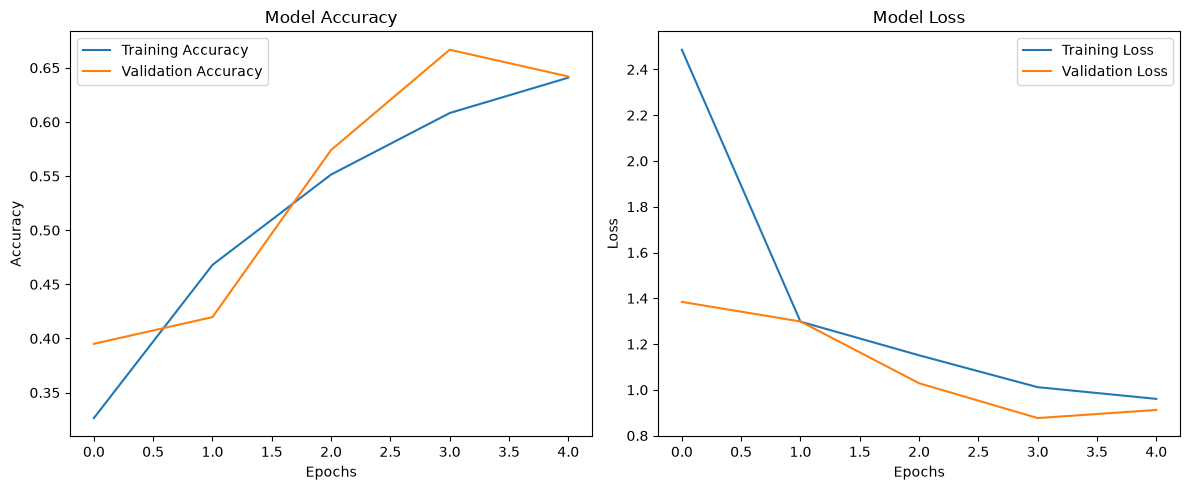

In [8]:
plt.figure(figsize=(12, 5))

# Accuracy
plt.subplot(1, 2, 1)

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title('Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

# Loss
plt.subplot(1, 2, 2)

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

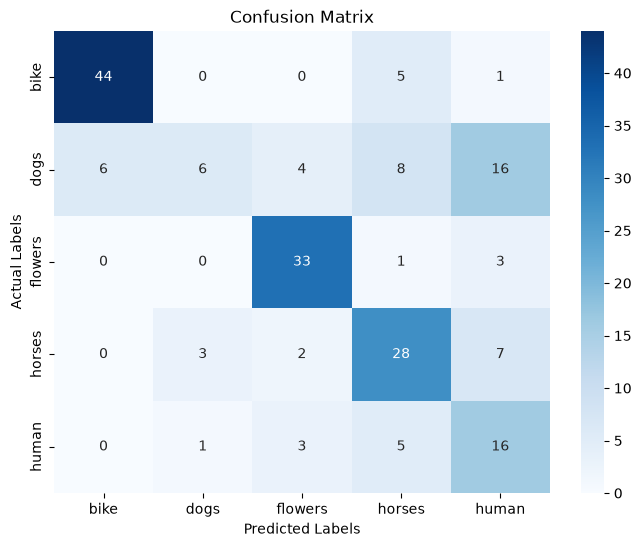

In [9]:
y_true = []
y_pred = []

for images, labels in test_ds:

    # Actual labels
    y_true.extend(np.argmax(labels.numpy(), axis=1))

    # Predicted labels
    predictions = model.predict(images, verbose=0)

    y_pred.extend(np.argmax(predictions, axis=1))

# Convert to NumPy arrays
y_true = np.array(y_true)
y_pred = np.array(y_pred)

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel('Predicted Labels')
plt.ylabel('Actual Labels')
plt.title('Confusion Matrix')

plt.show()

In [ ]:
## Calculate TP, TN, FP, FN for Bike
- True Positive = TP = Actual Bike correctly predicted as Bike.
- TP = 24
- False Positive = Other classes predicted as Bike.
- FP = 1+0+0+0 = 1
- False Negative =Actual Bike incorrectly predicted as other class.
- FN = 28+0+0+1 = 29
- True Negative = TN = All other classes correctly predicted as something other than Bike.
- TN = 224 -(TP+FP+FN) = 224 - (24+1+29) = 170

Vertical = FP
horizontal = FN

In [10]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_true, y_pred)

classes = ['bike', 'cars', 'flowers', 'horses', 'human']

total = cm.sum()

for i, class_name in enumerate(classes):

    TP = cm[i, i]

    FP = cm[:, i].sum() - TP

    FN = cm[i, :].sum() - TP

    TN = total - (TP + FP + FN)

    print(f"\nClass {class_name}")
    print("TP:", TP)
    print("TN:", TN)
    print("FP:", FP)
    print("FN:", FN)


Class bike
TP: 44
TN: 136
FP: 6
FN: 6

Class cars
TP: 6
TN: 148
FP: 4
FN: 34

Class flowers
TP: 33
TN: 146
FP: 9
FN: 4

Class horses
TP: 28
TN: 133
FP: 19
FN: 12

Class human
TP: 16
TN: 140
FP: 27
FN: 9


In [11]:
# Classification Report
print(classification_report(
    y_true,
    y_pred,
    target_names=class_names
))

              precision    recall  f1-score   support

        bike       0.88      0.88      0.88        50
        dogs       0.60      0.15      0.24        40
     flowers       0.79      0.89      0.84        37
      horses       0.60      0.70      0.64        40
       human       0.37      0.64      0.47        25

    accuracy                           0.66       192
   macro avg       0.65      0.65      0.61       192
weighted avg       0.68      0.66      0.64       192



In [12]:
model.save("D:/Deep Learning for Image/models/custom_api_model.keras")

In [15]:
from tensorflow.keras.models import load_model
# Load trained model
model = load_model(
    "D:/Deep Learning for Image/models/custom_api_model.keras"
)

# Class names (must follow training dataset order)
class_names = ['bike', 'dogs', 'flowers', 'horses', 'human']

# Image path
image_path = "D:/Deep Learning for Image/Test_Images/testimage.jpg"

# Load and resize image
img = tf.keras.utils.load_img(
    image_path,
    target_size=(224, 224)
)

# Convert image to array
img_array = tf.keras.utils.img_to_array(img)

# Add batch dimension
img_array = np.expand_dims(img_array, axis=0)

# VGG16 preprocessing
img_array = preprocess_input(img_array)

# Predict
prediction = model.predict(img_array)

# Get predicted class
predicted_index = np.argmax(prediction[0])

predicted_class = class_names[predicted_index]

confidence = prediction[0][predicted_index] * 100

print("Predicted Class:", predicted_class)
print("Confidence: {:.2f}%".format(confidence))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 140ms/step
Predicted Class: bike
Confidence: 65.89%
